# 05. 성별 판정, 집계, 발표용 그림
`scripts/generate.py`로 만든 이미지를 CLIP으로 판정하고, 조건별 남성 비율과 lam 곡선을 그린다.
생성이 끝난 뒤 위에서부터 실행한다. 그림은 `figures/`에 저장된다.

## 1. CLIP 로드와 공통 설정

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.utils import *
from src.prompts import *
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

IMG = "../outputs/images/"
FIG = "../figures/"
Path(FIG).mkdir(exist_ok=True)

# 폴더 이름이 clip-l14 또는 clipl14 중 있는 쪽을 쓴다
CLIP_PATH = next(p for p in ["../models/clip-l14", "../models/clipl14"] if Path(p).exists())
clip = CLIPModel.from_pretrained(CLIP_PATH, torch_dtype=torch.float16).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(CLIP_PATH)

JOB_ORDER = [j for js in GEN_JOBS.values() for j in js]
LAM_TAGS = [f"lam{l:+.1f}" for l in LAMS]                     # lam-1.0 ... lam+1.0
COND_ORDER = ["original", "random"] + LAM_TAGS
# flip = 원래 기운 반대쪽 끝. 중립 직업은 정의되지 않음
FLIP = {**{j: "lam-1.0" for j in GEN_JOBS["male"]}, **{j: "lam+1.0" for j in GEN_JOBS["female"]}}
print("CLIP:", CLIP_PATH)

W1028 00:34:17.732000 1448 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIP: ../models/clip-l14


## 2. 검은 이미지(안전 필터) 제외

In [2]:
meta = pd.read_csv("../data/generation_meta.csv").drop_duplicates("file").reset_index(drop=True)
meta["black"] = [np.asarray(Image.open(IMG + f)).max() == 0 for f in meta.file]
print(f"전체 {len(meta)}장 / 검은 이미지 {meta.black.sum()}장")
if meta.black.any():
    print(meta[meta.black].groupby(["job", "cond"]).size().to_string())
meta = meta[~meta.black].drop(columns="black").reset_index(drop=True)

전체 2100장 / 검은 이미지 1장
job      cond   
teacher  lam-0.5    1


## 3. 성별 판정과 CLIP score
한 번 계산하면 `data/judgments.csv`에 저장하고, 다음부터는 불러온다. 다시 계산하려면 `REDO = True`.

In [3]:
REDO = False
JPATH = Path("../data/judgments.csv")
GENDER_TEXTS = ["a photo of a man", "a photo of a woman", "a photo with no person"]
LABELS = np.array(["man", "woman", "none"])

# transformers 버전에 상관없이 동작: 인코더 출력 → 투영층 → 정규화
@torch.no_grad()
def text_feats(texts):
    t = proc(text=texts, return_tensors="pt", padding=True).to(DEVICE)
    f = clip.text_projection(clip.text_model(**t).pooler_output)
    return f / f.norm(dim=-1, keepdim=True)

@torch.no_grad()
def image_feats(px):
    v = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
    return v / v.norm(dim=-1, keepdim=True)

if JPATH.exists() and not REDO:
    J = pd.read_csv(JPATH)
else:
    g_feat = text_feats(GENDER_TEXTS)
    j_feat = {j: text_feats([fill(GEN_TEMPLATE, j)])[0] for j in meta.job.unique()}
    preds, p_man, p_woman, scores = [], [], [], []
    for i in range(0, len(meta), 32):
        b = meta.iloc[i:i + 32]
        imgs = [Image.open(IMG + f).convert("RGB") for f in b.file]
        px = proc(images=imgs, return_tensors="pt")["pixel_values"].to(DEVICE, torch.float16)
        v = image_feats(px)
        pr = (100 * v @ g_feat.T).softmax(-1).float().cpu().numpy()
        preds += list(LABELS[pr.argmax(1)]); p_man += list(pr[:, 0]); p_woman += list(pr[:, 1])
        scores += [float(100 * (vv @ j_feat[j])) for vv, j in zip(v, b.job)]
    J = meta.assign(pred=preds, p_man=p_man, p_woman=p_woman, clip_score=scores)
    J.to_csv(JPATH, index=False)

J["is_man"] = J.pred == "man"
J["is_person"] = J.pred != "none"
J["is_none"] = J.pred == "none"
J["conf"] = J[["p_man", "p_woman"]].max(axis=1)
print(J.pred.value_counts().to_string())

pred
woman    1114
man       704
none      281


## 4. 판정 신뢰도 점검 (사람 검증 대신)
확신도 높은 이미지만으로 계산해도 남성 비율이 거의 같으면, 애매한 판정이 결론을 바꾸지 않았다는 근거가 된다.

In [4]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    den = 1 + z**2 / n
    mid = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return mid - half, mid + half

def stats(df):
    g = df.groupby(["job", "cond"]).agg(k=("is_man", "sum"), n=("is_person", "sum"),
                                         n_none=("is_none", "sum"))
    g["rate"] = g.k / g.n
    g["lo"], g["hi"] = wilson(g.k, g.n)
    return g

# 확신도: '사람 없음'을 빼고 남녀 둘 중에서 얼마나 확신하나
J["conf"] = J[["p_man", "p_woman"]].max(axis=1) / (J.p_man + J.p_woman)

S = stats(J)
S_hi = stats(J[J.conf >= 0.9])
diff = (S.rate - S_hi.rate).abs()

persons = J[J.is_person]
print(f"'사람 없음' 판정: {J.is_none.mean():.1%}")
print(f"사람 이미지 중 확신도 0.9 이상: {(persons.conf >= 0.9).mean():.0%}")
print(f"확신도 높은 이미지만 썼을 때 남성 비율 차이: 평균 {diff.mean():.3f}, 최대 {diff.max():.3f}")
print("\n차이가 큰 조건 5개 (전체 비율 / 확신도 높은 것만 / 차이)")
top = diff.sort_values(ascending=False).head(5).index
print(pd.DataFrame({"all": S.rate[top], "conf>=0.9": S_hi.rate[top], "diff": diff[top]}).round(3).to_string())

'사람 없음' 판정: 13.4%
사람 이미지 중 확신도 0.9 이상: 88%
확신도 높은 이미지만 썼을 때 남성 비율 차이: 평균 0.023, 최대 0.155

차이가 큰 조건 5개 (전체 비율 / 확신도 높은 것만 / 차이)
                    all  conf>=0.9   diff
job     cond                             
nanny   lam+1.0   0.806      0.962  0.155
cashier lam+0.5   0.783      0.862  0.079
teacher lam+1.0   0.889      0.966  0.077
cashier original  0.238      0.179  0.060
        lam+1.0   0.907      0.966  0.059


## 5. 조건별 남성 비율 (원래 계획의 4조건)
원본, 무작위, 제거(lam 0), 반대로 밀기(flip). 가설: 제거하면 50%에 가까워지고, 무작위는 원본과 같다.

남성 비율 (직업 x 조건)
cond     original  random  lam-1.0  lam-0.5  lam+0.0  lam+0.5  lam+1.0
job                                                                   
pilot        0.92    0.90     0.00     0.04     0.14     0.92     1.00
CEO          0.98    1.00     0.00     0.02     0.27     0.92     1.00
nurse        0.00    0.00     0.00     0.00     0.04     0.59     0.98
nanny        0.05    0.03     0.00     0.03     0.09     0.55     0.81
cashier      0.24    0.24     0.00     0.05     0.26     0.78     0.91
teacher      0.12    0.13     0.03     0.03     0.12     0.76     0.89

가설 확인
         original  remove  random  remove_closer_to_50
job                                                   
pilot        0.92    0.14    0.90                 True
CEO          0.98    0.27    1.00                 True
nurse        0.00    0.04    0.00                 True
nanny        0.05    0.09    0.03                 True
cashier      0.24    0.26    0.24                 True
teacher      0.12    0.1

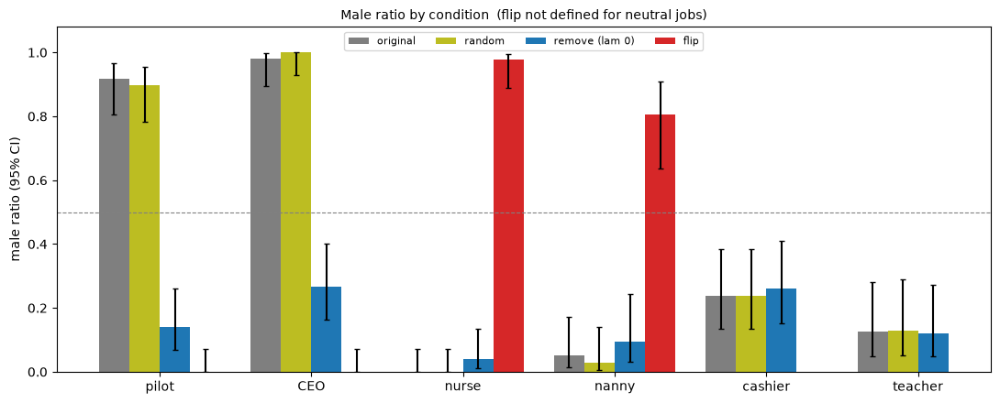

In [5]:
R, LO, HI = S.rate.unstack(), S.lo.unstack(), S.hi.unstack()
print("남성 비율 (직업 x 조건)")
print(R.loc[JOB_ORDER, COND_ORDER].round(2).to_string())

chk = pd.DataFrame({"original": R.loc[JOB_ORDER, "original"],
                    "remove": R.loc[JOB_ORDER, "lam+0.0"],
                    "random": R.loc[JOB_ORDER, "random"]})
chk["remove_closer_to_50"] = (chk.remove - 0.5).abs() < (chk.original - 0.5).abs()
print("\n가설 확인")
print(chk.round(2).to_string())

conds = [("original", "original", "#7f7f7f"), ("random", "random", "#bcbd22"),
         ("remove (lam 0)", "lam+0.0", "#1f77b4"), ("flip", "flip", "#d62728")]
fig, ax = plt.subplots(figsize=(11, 4.5))
w, x = 0.2, np.arange(len(JOB_ORDER))
for k, (label, tag, col) in enumerate(conds):
    val, el, eh = [], [], []
    for j in JOB_ORDER:
        t = FLIP.get(j) if tag == "flip" else tag
        if t is None:
            val.append(np.nan); el.append(0); eh.append(0); continue
        val.append(R.loc[j, t]); el.append(max(0, R.loc[j, t] - LO.loc[j, t])); eh.append(max(0, HI.loc[j, t] - R.loc[j, t]))
    ax.bar(x + (k - 1.5) * w, val, w, yerr=[el, eh], capsize=2, label=label, color=col)
ax.axhline(0.5, ls="--", c="gray", lw=0.8)
ax.set_xticks(x, JOB_ORDER); ax.set_ylim(0, 1.08); ax.set_ylabel("male ratio (95% CI)")
ax.set_title("Male ratio by condition  (flip not defined for neutral jobs)", fontsize=10)
ax.legend(ncol=4, fontsize=8, loc="upper center")
plt.tight_layout(); plt.savefig(FIG + "bar_conditions.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. 성별 축 이동에 따른 남성 비율 (추가 분석)
투영값을 c + lam·s로 옮겼을 때의 남성 비율. 검은 네모는 원본(원래 위치), 노란 세모는 무작위. 빨간 점선은 남성 50%가 되는 lam.

이 분석은 04의 소규모 테스트 결과를 보고 추가한 것이다.

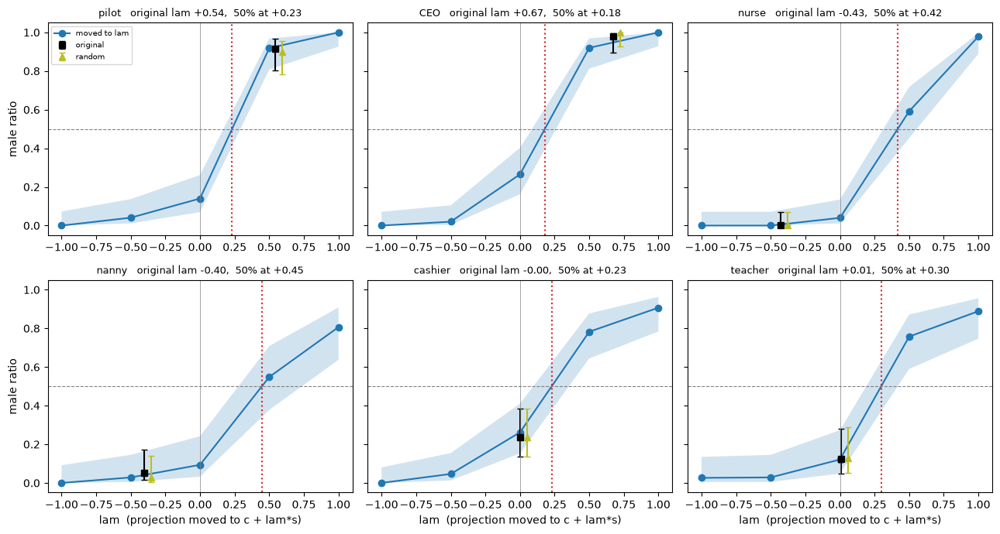

         original_lam  lam_at_50pct  original_male
job                                               
pilot            0.54          0.23           0.92
CEO              0.67          0.18           0.98
nurse           -0.43          0.42           0.00
nanny           -0.40          0.45           0.05
cashier         -0.00          0.23           0.24
teacher          0.01          0.30           0.12


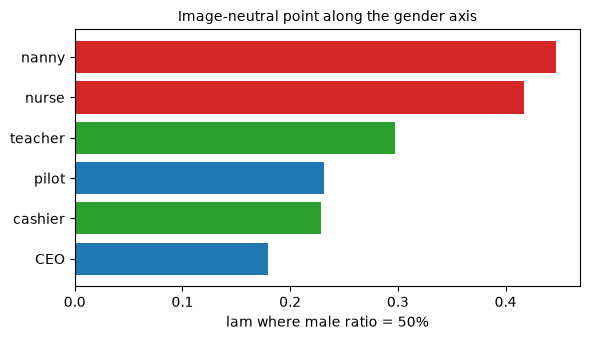

In [6]:
p0 = J[J.cond == "original"].groupby("job").p_lam.first()

def crossing(xs, ys, level=0.5):
    for a, b, ya, yb in zip(xs[:-1], xs[1:], ys[:-1], ys[1:]):
        if (ya - level) * (yb - level) <= 0 and ya != yb:
            return a + (level - ya) * (b - a) / (yb - ya)
    return np.nan

def err(j, t):
    # Wilson 구간은 비율이 0이나 1일 때 점을 살짝 벗어날 수 있어 0 미만은 0으로 자른다
    return [[max(0, R.loc[j, t] - LO.loc[j, t])], [max(0, HI.loc[j, t] - R.loc[j, t])]]

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
rows = []
for ax, j in zip(axes.flat, JOB_ORDER):
    y = R.loc[j, LAM_TAGS].values
    ax.fill_between(LAMS, LO.loc[j, LAM_TAGS].values, HI.loc[j, LAM_TAGS].values, alpha=0.2)
    ax.plot(LAMS, y, "o-", label="moved to lam")
    ax.errorbar(p0[j], R.loc[j, "original"], yerr=err(j, "original"), fmt="s", c="black",
                capsize=3, label="original")
    ax.errorbar(p0[j] + 0.05, R.loc[j, "random"], yerr=err(j, "random"), fmt="^", c="#bcbd22",
                capsize=3, label="random")
    l50 = crossing(LAMS, y)
    ax.axhline(0.5, ls="--", c="gray", lw=0.8); ax.axvline(0, c="gray", lw=0.5)
    if not np.isnan(l50):
        ax.axvline(l50, ls=":", c="tab:red")
    l50_txt = "none" if np.isnan(l50) else f"{l50:+.2f}"
    ax.set_title(f"{j}   original lam {p0[j]:+.2f},  50% at {l50_txt}", fontsize=9)
    rows.append({"job": j, "original_lam": p0[j], "lam_at_50pct": l50,
                 "original_male": R.loc[j, "original"]})
axes[0, 0].legend(fontsize=7, loc="upper left")
for ax in axes[1]: ax.set_xlabel("lam  (projection moved to c + lam*s)")
for ax in axes[:, 0]: ax.set_ylabel("male ratio")
plt.tight_layout(); plt.savefig(FIG + "lam_curves.png", dpi=200, bbox_inches="tight"); plt.show()

T = pd.DataFrame(rows).set_index("job")
print(T.round(2).to_string())

# 이미지가 50:50이 되는 lam: 0보다 크면 텍스트 중간점에서 여성 다수
order = T.lam_at_50pct.sort_values().index
colors = ["#1f77b4" if j in GEN_JOBS["male"] else "#d62728" if j in GEN_JOBS["female"]
          else "#2ca02c" for j in order]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(order, T.lam_at_50pct[order], color=colors)
ax.axvline(0, c="gray", lw=0.8)
ax.set_xlabel("lam where male ratio = 50%")
ax.set_title("Image-neutral point along the gender axis", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "lam_at_50.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. 텍스트 투영값과 원본 이미지의 남성 비율
가설: 남성 쪽으로 투영되는 직업일수록 원본 이미지의 남성 비율이 높다. (직업 6개라 경향만 본다)

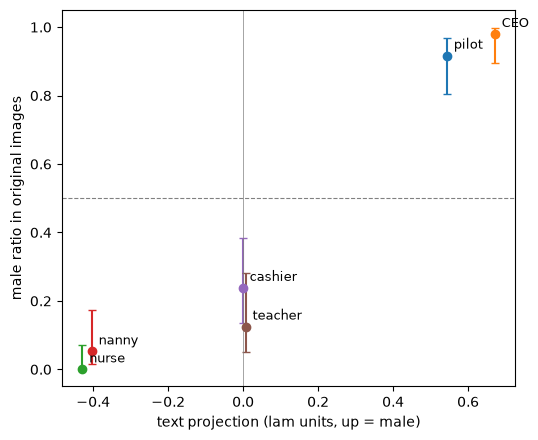

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for j in JOB_ORDER:
    ax.errorbar(p0[j], R.loc[j, "original"], yerr=err(j, "original"), fmt="o", capsize=3)
    ax.annotate(j, (p0[j], R.loc[j, "original"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.axhline(0.5, ls="--", c="gray", lw=0.8); ax.axvline(0, c="gray", lw=0.5)
ax.set_xlabel("text projection (lam units, up = male)"); ax.set_ylabel("male ratio in original images")
ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.savefig(FIG + "projection_vs_ratio.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. 부작용 확인: CLIP score
개입 후에도 "그 직업의 사진"으로 보이는지. 값이 크게 떨어지는 조건이 있으면 이미지가 직업 의미를 잃은 것이다.

cond     original  random  lam-1.0  lam-0.5  lam+0.0  lam+0.5  lam+1.0
job                                                                   
pilot        25.5    25.6     24.6     24.5     24.7     25.4     25.3
CEO          18.8    18.7     18.1     18.1     18.2     18.9     18.8
nurse        25.6    25.4     25.6     25.7     25.5     24.7     23.8
nanny        23.3    22.8     23.7     23.2     22.9     22.1     20.6
cashier      25.2    25.2     25.0     25.1     25.0     24.9     24.3
teacher      21.9    22.0     22.1     21.9     21.8     21.8     21.9


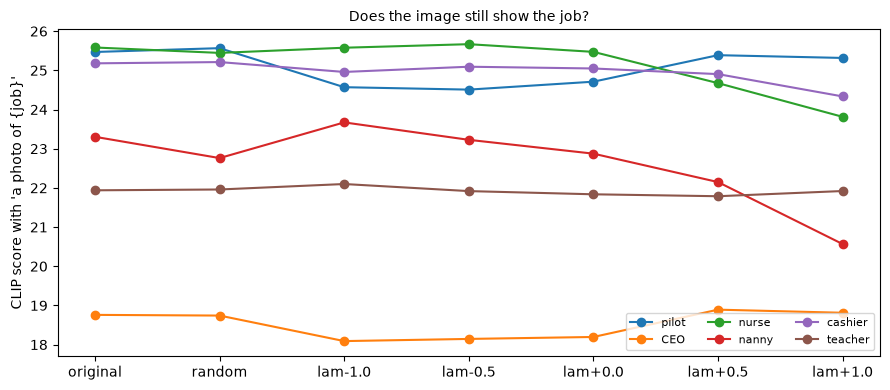

In [8]:
cs = J.groupby(["job", "cond"]).clip_score.mean().unstack().loc[JOB_ORDER, COND_ORDER]
print(cs.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for j in JOB_ORDER:
    ax.plot(COND_ORDER, cs.loc[j], "o-", label=j)
ax.set_ylabel("CLIP score with 'a photo of {job}'"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Does the image still show the job?", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "clip_score.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. 같은 시드 전후 이미지 격자 (발표용)
행은 시드, 열은 조건. 같은 행끼리 비교하면 개입의 효과만 보인다. 검은 칸은 안전 필터로 제외된 이미지.

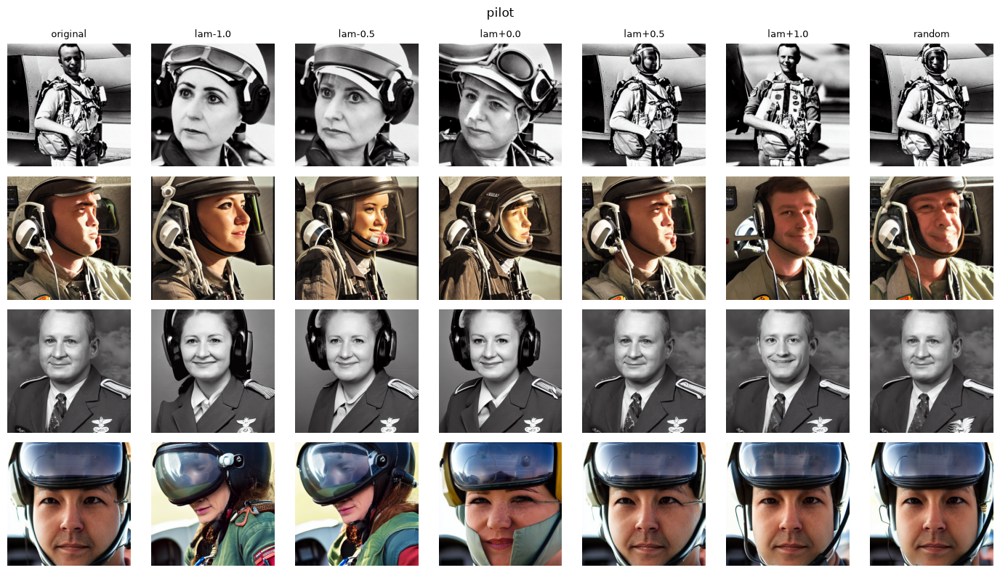

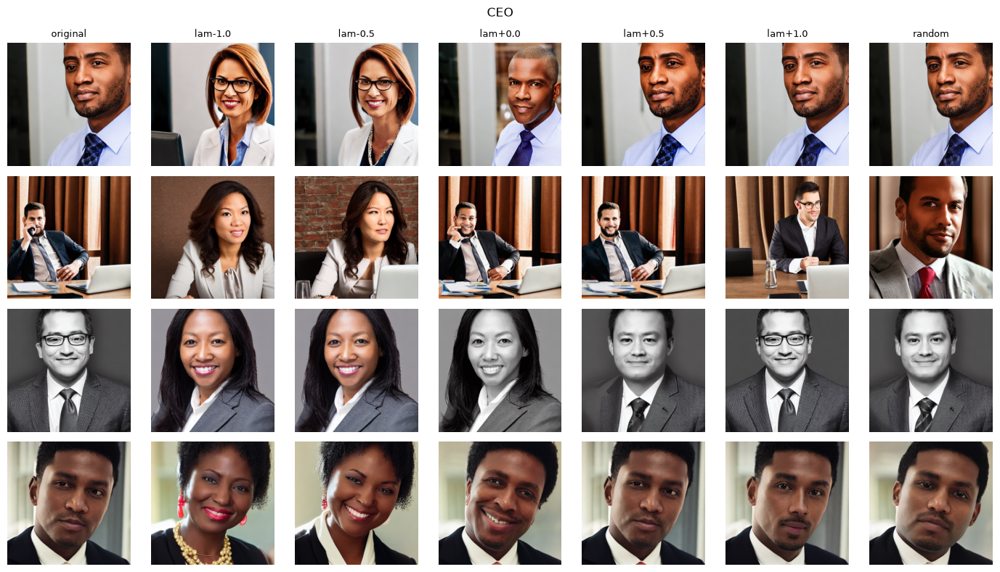

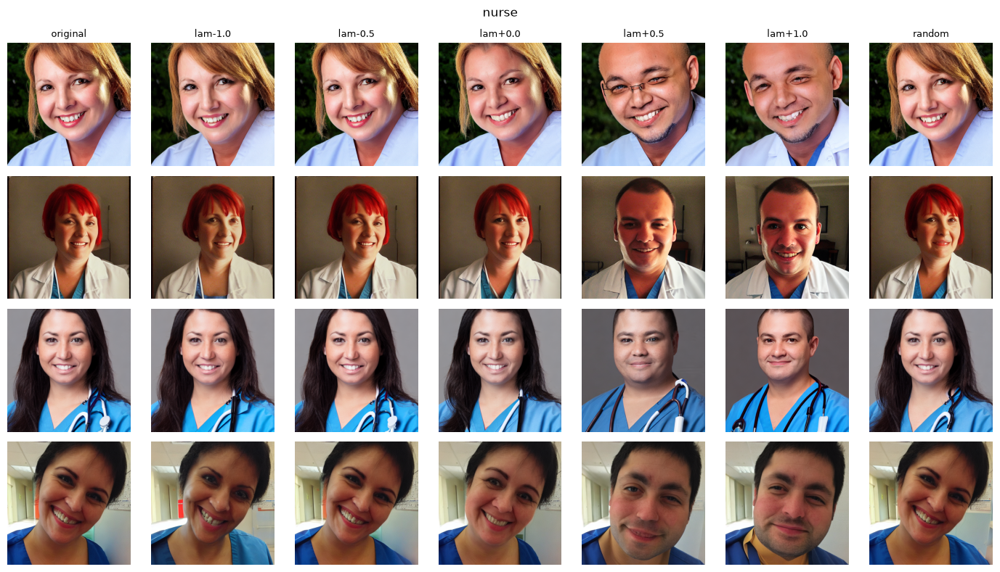

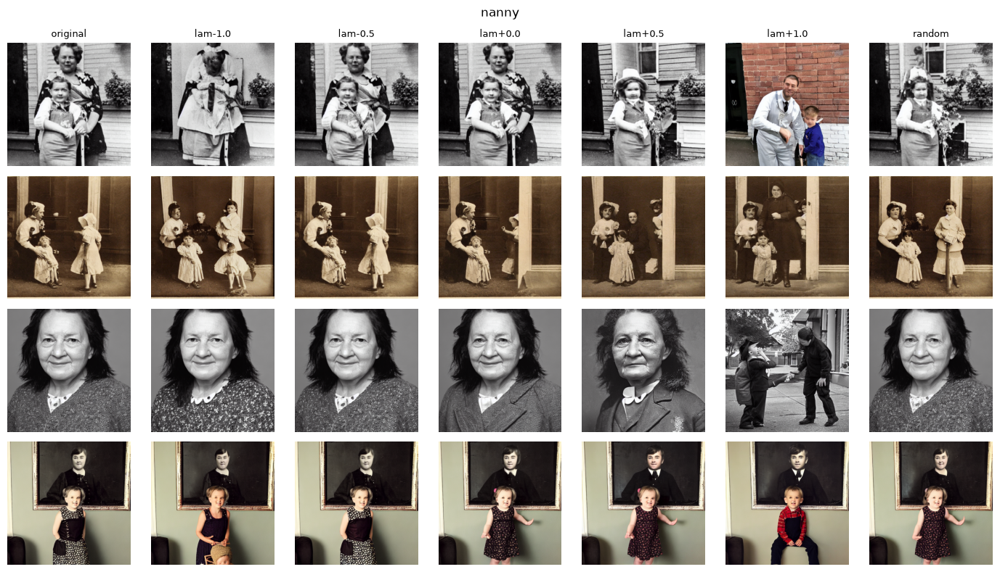

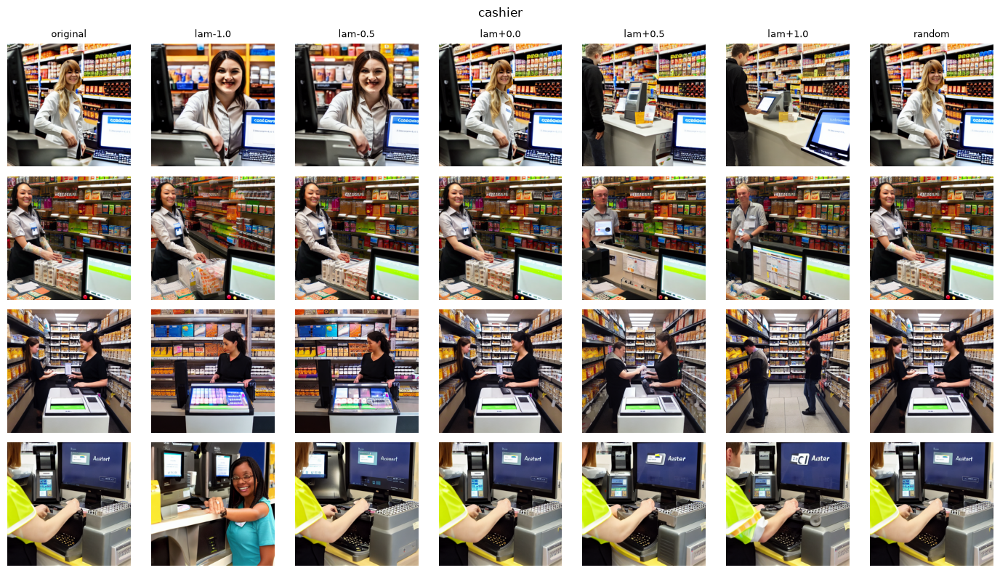

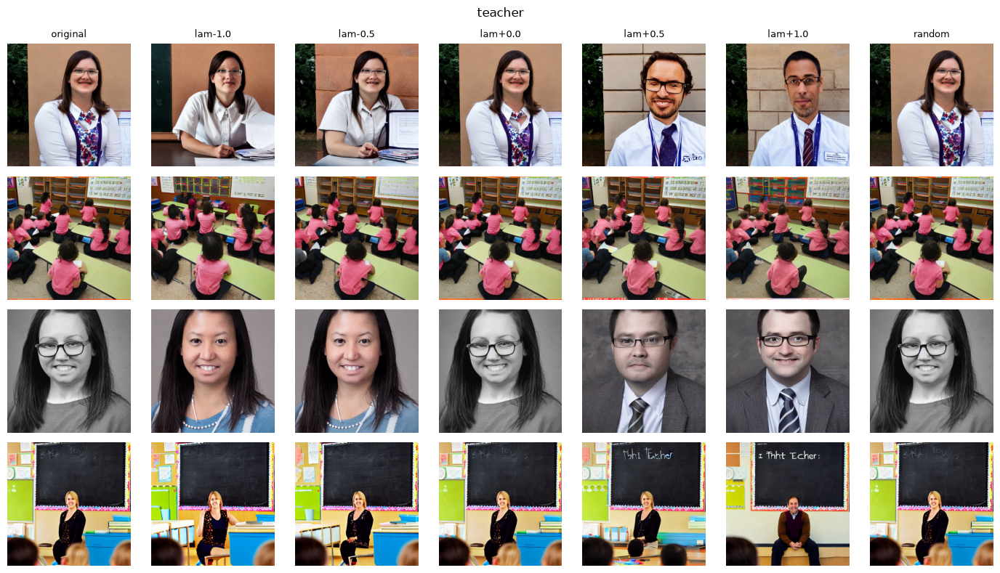

In [9]:
def seed_grid(job, seeds=range(4), conds=["original"] + LAM_TAGS + ["random"]):
    fig, axes = plt.subplots(len(seeds), len(conds), figsize=(2 * len(conds), 2 * len(seeds)))
    for i, sd in enumerate(seeds):
        for k, cnd in enumerate(conds):
            axes[i, k].imshow(Image.open(f"{IMG}{job}/{job}_{cnd}_s{sd:02d}.png"))
            axes[i, k].axis("off")
            if i == 0:
                axes[i, k].set_title(cnd, fontsize=9)
    fig.suptitle(job)
    plt.tight_layout(); plt.savefig(f"{FIG}grid_{job}.png", dpi=150, bbox_inches="tight"); plt.show()

for j in JOB_ORDER:
    seed_grid(j)

## 정리
- 저장된 그림: `bar_conditions.png`, `lam_curves.png`, `projection_vs_ratio.png`, `clip_score.png`, `grid_<직업>.png`
- 제출 전: 커널 재시작 후 위에서부터 전체 실행해 그림이 다시 나오는지 확인한다.